# Mini Challenge 2026 – Hotel revenue forecasting

**Task:** produce 1-7 days ahead forecasts of the daily `Revenue` of upper-middle class hotels in one US city, using data between 2013 and 2020.

The city is not fixed in advance: we load all 8 cities, compare them in the EDA (section 2.1) and pick the one with the most regular, forecastable signal.

Pipeline:
1. Data loading
2. Exploratory analysis
3. Transformations and stationarity
4. Cross-validation setup and baselines
5. Model building (ETS, ARIMA)
6. Results: model selection, diagnostics, example forecasts

Runtime: ≈ 1-2 minutes (almost all of it is the AutoARIMA order search in section 5).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from scipy.stats import boxcox
from scipy.signal import periodogram
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import MSTL
import statsmodels.api as sm
from statsforecast.models import AutoETS, AutoARIMA     # pip install statsforecast
from statsforecast.arima import arima_string

warnings.filterwarnings('ignore')   # KPSS warns when the p-value is outside its lookup table
plt.rcParams['figure.figsize'] = (14, 4)

## 1. Data loading
The pickle contains all cities stacked in long format (`Location` column). We pivot `Revenue` to one column per city over 2013-2020 (Atlanta starts in 2012, we drop that year) and set a daily frequency: `asfreq('D')` would expose missing days as NaN.

In [2]:
df = pd.read_pickle('Data/hotels.pk')
rev = df.pivot(columns='Location', values='Revenue').loc['2013':'2020'].asfreq('D')

COVID = '2020-03-01'                 # start of the structural break (see plots below)
print(rev.shape, '| missing values:', rev.isna().sum().sum())
rev.describe().T

(2861, 8) | missing values: 0


,count,mean,std,min,25%,50%,75%,max
Location,,,,,,,,
Atlanta,2861.0,1.214674e+06,4.040645e+05,300130.994748,9.193944e+05,1.181489e+06,1.496782e+06,3.527372e+06
Boston,2861.0,8.151052e+05,3.765285e+05,114523.553351,5.037029e+05,7.861201e+05,1.087058e+06,2.035877e+06
Chicago,2861.0,1.275021e+06,5.327550e+05,191560.618017,8.693120e+05,1.235056e+06,1.649091e+06,3.194662e+06
Dallas,2861.0,9.534181e+05,3.138103e+05,246828.548026,7.192026e+05,9.331464e+05,1.171726e+06,2.042266e+06
LosAngeles,2861.0,1.047586e+06,3.072564e+05,164409.176800,8.223213e+05,1.029759e+06,1.284525e+06,1.839768e+06
NewYork,2861.0,3.152937e+06,1.208497e+06,588695.817812,2.275864e+06,3.191277e+06,3.961953e+06,7.940696e+06
Orlando,2861.0,1.860535e+06,6.914702e+05,88994.827420,1.484438e+06,1.885469e+06,2.270487e+06,4.346277e+06
Washington,2861.0,1.527573e+06,5.976716e+05,275723.044727,1.074773e+06,1.516478e+06,1.933002e+06,3.974323e+06


## 2. Exploratory analysis
### 2.1 Comparing the cities and choosing one
All cities share the COVID break, so we compare them on the pre-COVID period (2013-2019), each scaled by its mean to make the levels comparable.

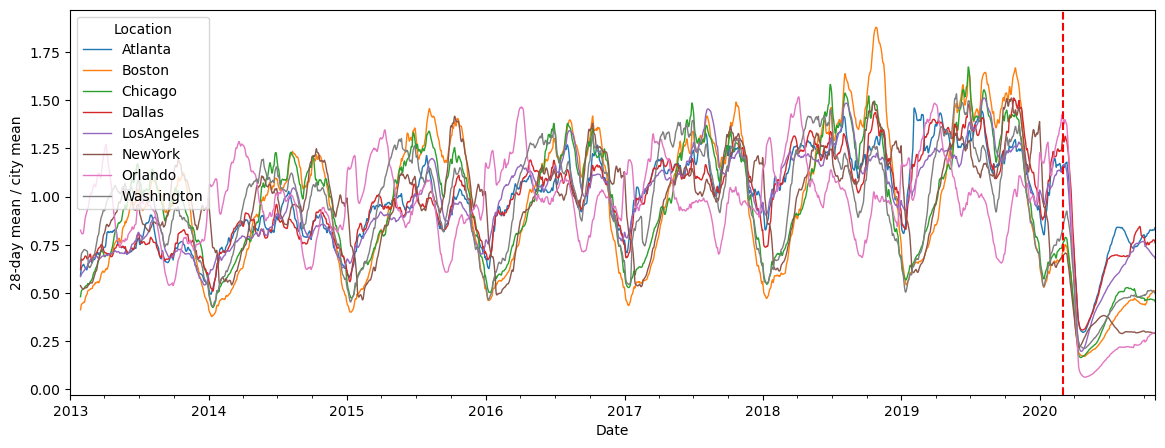

In [3]:
(rev / rev.loc[:'2019'].mean()).rolling(28).mean().plot(lw=1, figsize=(14, 5))
plt.axvline(COVID, c='r', ls='--'); plt.ylabel('28-day mean / city mean');

Forecastability indicators per city (pre-COVID):
* **ACF at lag 7 / 364**: strength of the weekly / yearly pattern.
* **CV**: coefficient of variation (std / mean), a measure of noisiness.
* **Variance ratio** $\operatorname{Var}(\Delta y_t) / \operatorname{Var}(y_t)$: error variance of the naive forecast relative to the series variance (lower = smoother, more forecastable).
* **Spectral entropy** $H = -\frac{1}{\log K}\sum_i p_i \log p_i$, with $p_i$ the normalised periodogram: low when the power is concentrated in a few periodicities (more forecastable).
* **MAPE of the seasonal naive (lag 7) on 2019**: how hard the series is for the simplest seasonal forecaster.

We pick the city with the lowest seasonal-naive MAPE, i.e. the most regular signal.

In [4]:
pre = rev.loc[:'2019']
def spec_entropy(s):
    p = periodogram(s - s.mean())[1][1:]           # drop the zero frequency
    p = p / p.sum()
    return -(p * np.log(p + 1e-12)).sum() / np.log(len(p))

snaive_mape = lambda s: (abs(s - s.shift(7)) / s).loc['2019'].mean() * 100
stats = pd.DataFrame({
    'ACF lag 7':   pre.apply(lambda s: s.autocorr(7)),
    'ACF lag 364': pre.apply(lambda s: s.autocorr(364)),
    'CV':          pre.std() / pre.mean(),
    'Var ratio':   pre.diff().var() / pre.var(),
    'Spec entropy': pre.apply(spec_entropy),
    'MAPE snaive7 2019 [%]': pre.apply(snaive_mape),
}).sort_values('MAPE snaive7 2019 [%]').round(3)

CITY = stats.index[0]
print('Selected city:', CITY)
stats

Selected city: LosAngeles


,ACF lag 7,ACF lag 364,CV,Var ratio,Spec entropy,MAPE snaive7 2019 [%]
Location,,,,,,
LosAngeles,0.826,0.920,0.261,0.352,0.450,12.119
Dallas,0.735,0.893,0.309,0.573,0.537,17.865
Orlando,0.559,0.807,0.277,0.380,0.567,19.292
NewYork,0.681,0.903,0.318,0.411,0.506,19.504
Atlanta,0.639,0.837,0.316,0.568,0.577,20.244
Boston,0.807,0.905,0.414,0.320,0.400,21.526
Washington,0.714,0.890,0.345,0.382,0.488,21.677
Chicago,0.698,0.901,0.371,0.475,0.457,22.337


**Observations:**
* All cities share the same broad shape: growth to ~2017, summer peak, and the March 2020 collapse.
* Los Angeles has the strongest weekly autocorrelation and by far the lowest seasonal-naive error (12% vs ≥ 18%).
* On the two a-priori indicators of the course LA is second, just behind **Boston** (variance ratio 0.35 vs 0.32, spectral entropy 0.45 vs 0.40). Boston has the largest yearly swing (highest CV): a strong, smooth yearly cycle concentrates the spectrum and keeps day-to-day changes small relative to the total variance, but it does not make the 1-7 day forecast easier (its seasonal-naive error is 21.5%).
* As in the course, a-priori indicators give a quick overview, but the a-posteriori test with a forecaster is the final check. Since our task is short-horizon, we select on the seasonal-naive error → **Los Angeles**, which is also in the top two on every other indicator.
* The rest of the notebook only depends on `CITY`, so another city can be analysed by changing that variable.

In [5]:
data = df[df['Location'] == CITY].drop(columns='Location').loc['2013':'2020'].asfreq('D')
y = data['Revenue']
y_pre = y.loc[:'2019-12-31']         # "regular" regime, used for analysis and model selection

### 2.2 Time plot

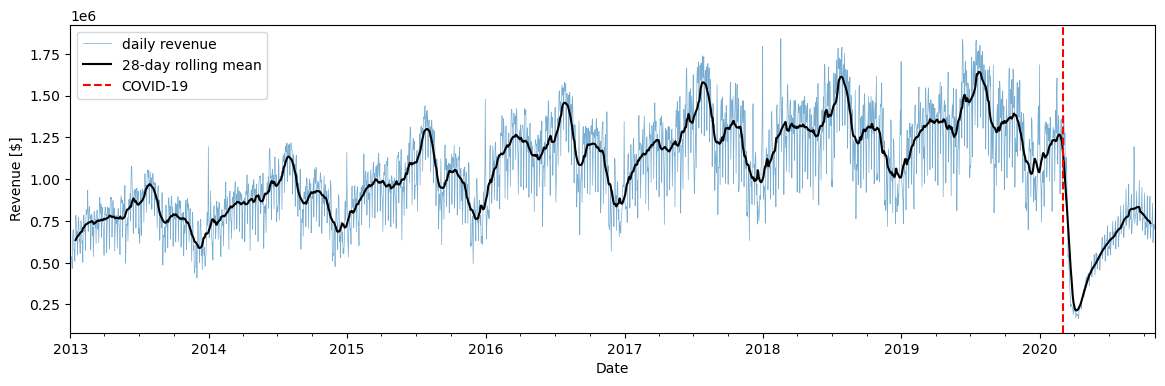

In [6]:
ax = y.plot(lw=0.5, alpha=0.6, label='daily revenue')
y.rolling(28, center=True).mean().plot(ax=ax, c='k', label='28-day rolling mean')
ax.axvline(COVID, c='r', ls='--', label='COVID-19')
ax.set_ylabel('Revenue [$]'); ax.legend();

**Observations:**
* Upward trend 2013-2017 that flattens from 2018.
* Clear yearly pattern: summer peak (Jul-Aug), dip at the end of the year.
* Strong weekly oscillation, whose amplitude grows with the level (multiplicative behaviour).
* March 2020: revenue collapses by ~85% (to ~200k $) and recovers only partially by October.

### 2.3 Calendar distributions
Boxplots by day of week and by month (pre-COVID only, to avoid mixing the two regimes).

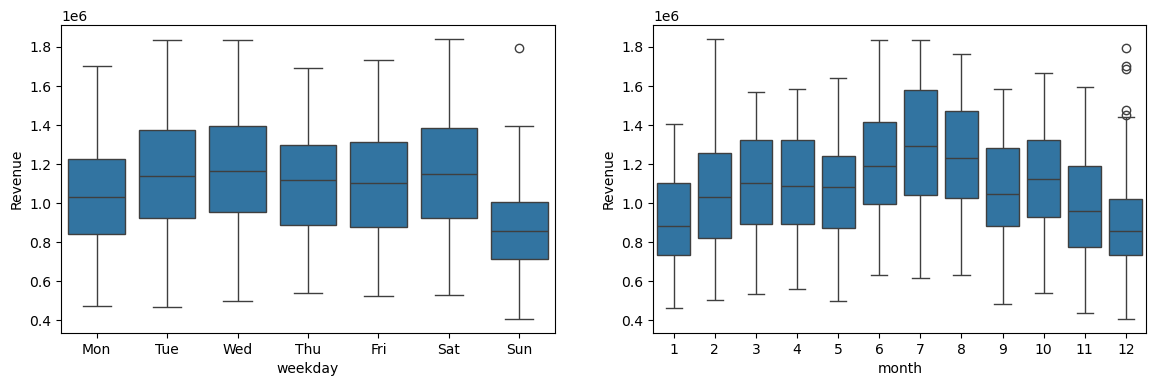

In [7]:
cal = pd.DataFrame({'Revenue': y_pre, 'weekday': y_pre.index.day_name().str[:3], 'month': y_pre.index.month})
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sb.boxplot(cal, x='weekday', y='Revenue', ax=ax[0], order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
sb.boxplot(cal, x='month', y='Revenue', ax=ax[1]);

**Observations:**
* Weekly seasonality: Sunday is clearly the weakest day, Monday the second weakest; Tue, Wed and Sat are the strongest.
* Yearly seasonality: high season in Jun-Aug, low in Jan and Dec (with a few high outliers in December, i.e. holiday days).

### 2.4 Correlation with the other variables
`Demand` (rooms sold) and `Occupancy` are known only up to today, so they can be used as **lagged** exogenous features, not as same-day regressors.

           Revenue  Demand  Occupancy
Revenue       1.00    0.96       0.76
Demand        0.96    1.00       0.86
Occupancy     0.76    0.86       1.00


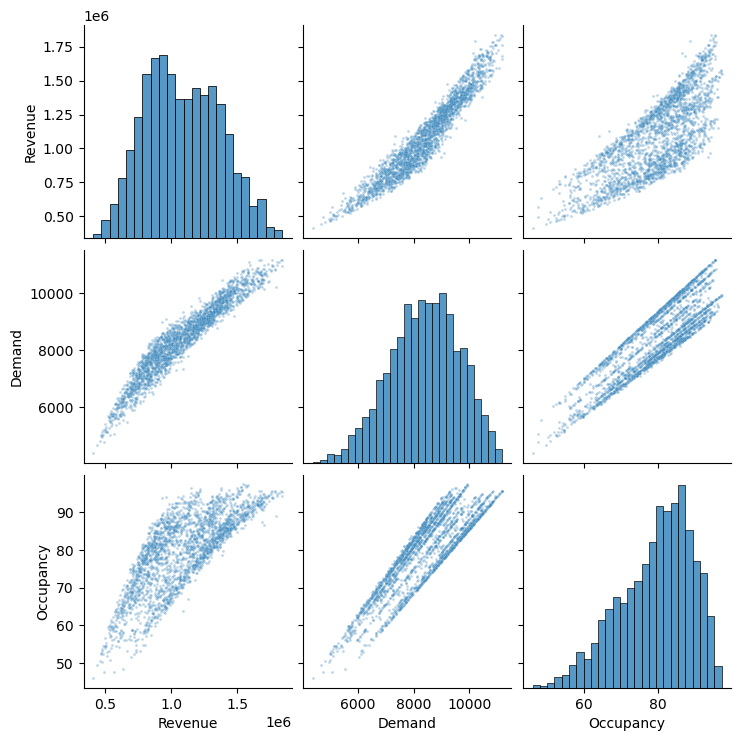

In [8]:
print(data.loc[:'2019'].corr().round(2))
sb.pairplot(data.loc[:'2019'], plot_kws=dict(s=4, alpha=0.3), height=2.5);

**Observations:**
* Revenue is almost proportional to Demand (ρ = 0.96): revenue ≈ rooms sold × average price. Occupancy is less correlated (ρ = 0.76).
* Since all three move together, lagged Demand brings little information that lagged Revenue does not already contain.

### 2.5 ACF / PACF
Short lags (weekly structure) and long lags (yearly structure, 364 = 52 weeks keeps the weekday aligned).

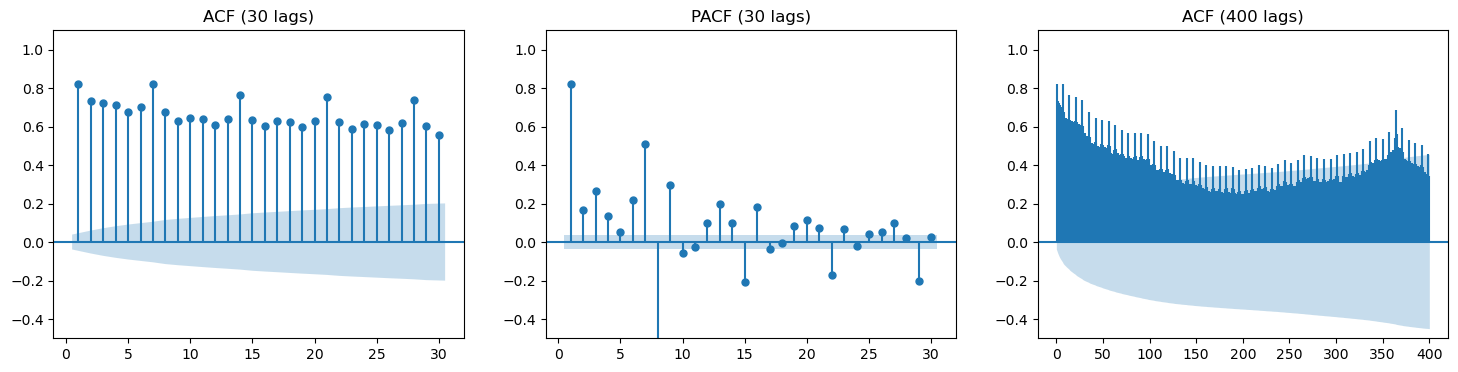

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
plot_acf(y_pre, lags=30, zero=False, ax=ax[0], title='ACF (30 lags)')
plot_pacf(y_pre, lags=30, zero=False, ax=ax[1], title='PACF (30 lags)')
plot_acf(y_pre, lags=400, zero=False, ax=ax[2], title='ACF (400 lags)', marker=None)
for a in ax: a.set_ylim(-0.5, 1.1)

**Observations:**
* The ACF decays very slowly with peaks at 7, 14, 21, 28: trend + weekly seasonality, the series is non-stationary.
* PACF: large spike at lag 1, then significant values at lags 7-9 (strongly negative at 8): typical of a seasonal AR/MA structure with $m=7$.
* Long lags: the ACF rises again around 364: yearly seasonality.

### 2.6 Decomposition
MSTL separates trend, weekly (7) and yearly (365) seasonality. We decompose the log series, where the seasonal effects become additive (see 3.1).

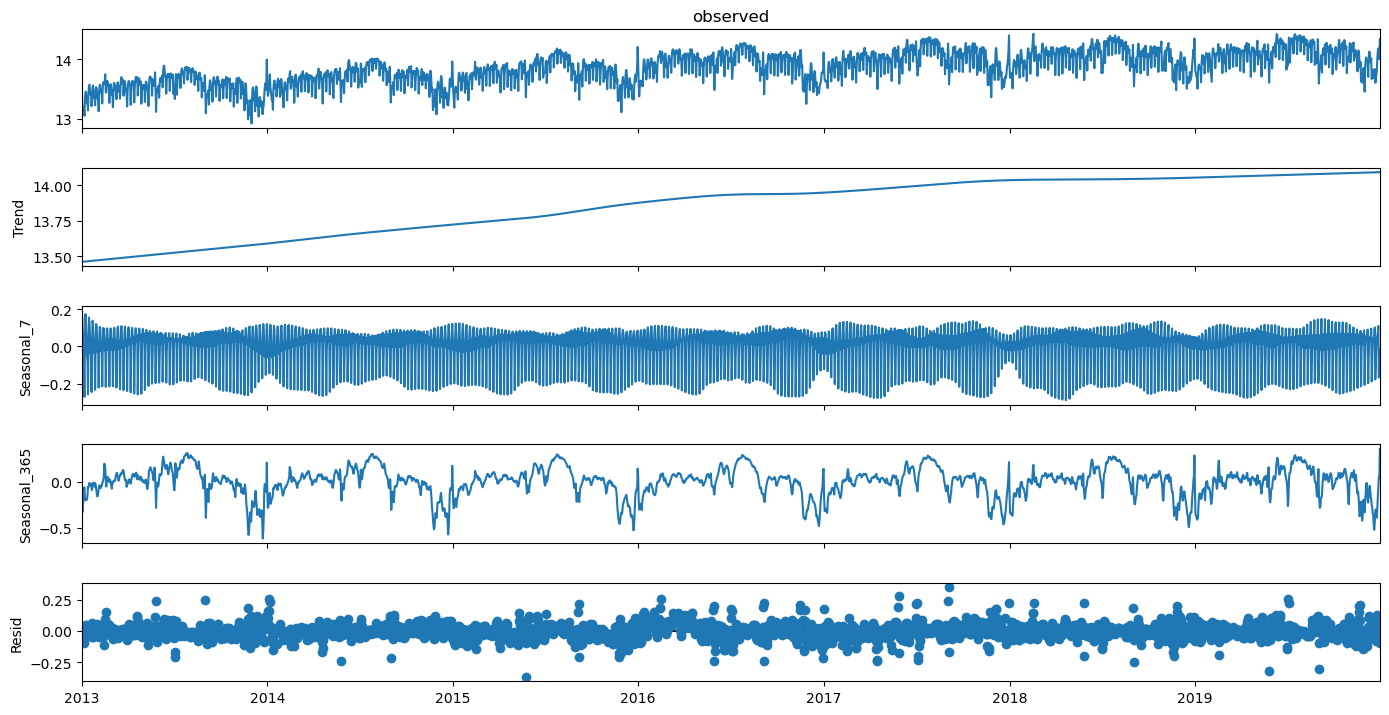

In [10]:
MSTL(np.log(y_pre), periods=(7, 365)).fit().plot().set_size_inches(14, 8)

## 3. Transformations and stationarity
### 3.1 Variance stabilisation
If the local standard deviation grows with the local level, a log / Box-Cox transform makes the variance (and the seasonal amplitude) roughly constant.

Box-Cox lambda (MLE) = 0.58   (0 = log)


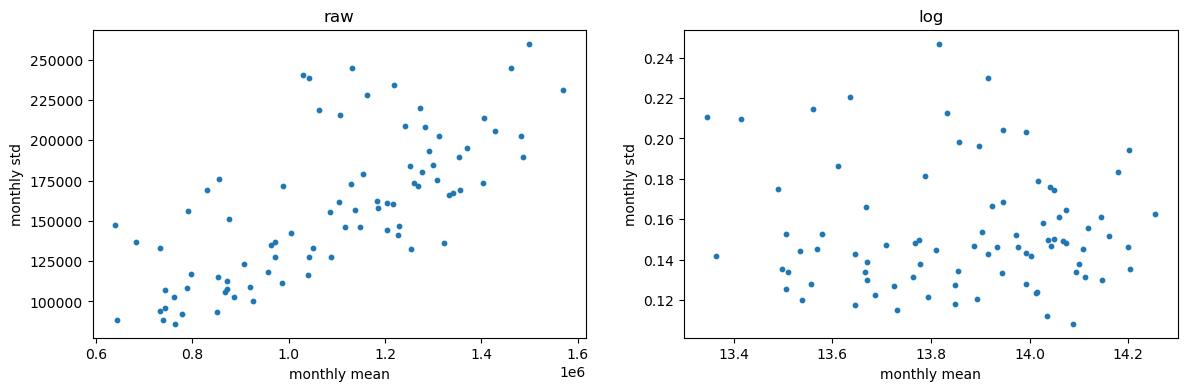

In [11]:
lam = boxcox(y_pre.values)[1]
print(f'Box-Cox lambda (MLE) = {lam:.2f}   (0 = log)')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, s, name in zip(ax, [y_pre, np.log(y_pre)], ['raw', 'log']):
    r = s.resample('ME')                        # monthly mean vs monthly std
    a.scatter(r.mean(), r.std(), s=10)
    a.set(xlabel='monthly mean', ylabel='monthly std', title=name)

**Observations:**
* Raw series: the monthly std grows linearly with the monthly mean → heteroscedastic.
* After the log the std no longer depends on the level, so the log is a reasonable choice (the MLE λ = 0.58 is in between; log is easier to interpret and back-transform).

### 3.2 Stationarity tests
| Test | H0 | H1 |
|---|---|---|
| ADF | non-stationary (unit root) | stationary |
| KPSS | (level) stationary | non-stationary |

A series looks stationary when ADF p-value is small **and** KPSS p-value is large.

In [12]:
ly = np.log(y_pre)
candidates = {'y': y_pre, 'log y': ly,
              'Δ7 log y': ly.diff(7), 'Δ1 Δ7 log y': ly.diff(7).diff()}
pd.DataFrame({k: {'adf pval': adfuller(s.dropna())[1], 'kpss pval': kpss(s.dropna())[1]}
              for k, s in candidates.items()}).T.round(3)

,adf pval,kpss pval
y,0.076,0.01
log y,0.083,0.01
Δ7 log y,0.000,0.10
Δ1 Δ7 log y,0.000,0.10


**Observations:**
* `y` and `log y`: ADF does not reject the unit root at 5% and KPSS rejects stationarity → non-stationary.
* A single seasonal difference (`Δ7 log y`) is enough: ADF rejects, KPSS does not (0.10 is the upper bound of its table). Candidate ARIMA setting: $d=0, D=1, m=7$ on log y.
* **Box-Cox / log does not induce stationarity:** it only stabilises the variance (3.1). `log y` still has trend and seasonality; differencing is what removes them.
* **Why we care:** we observe a single realisation of the process, so its mean and autocorrelation can only be estimated by averaging over time, which is meaningful only if the process is stationary (and ergodic). ARIMA also assumes a stationary series after differencing. The 2020 break is the counterexample: the past no longer describes the future and every model estimated on it degrades (section 6).

## 4. Cross-validation setup and baselines
### 4.1 How to handle COVID
The 2020 collapse is an exogenous structural break that no model trained on 2013-2019 can anticipate. We therefore:
* **select models** with a rolling-origin CV on **2019**;
* use **2020** as a separate **stress test**, to show how each model reacts to the break.

### 4.2 Rolling-origin (expanding window) CV
At every day $t$ of the CV period the forecaster sees $y_{\le t}$ and predicts $t+1, \dots, t+7$. Any forecaster with signature `f(y_train, h) -> array` can be plugged in, so the same function is reused for baselines and statistical models. `step` allows to skip origins for slow models.

In [13]:
H = 7

def rolling_cv(y, forecaster, start, end, h=H, step=1):
    '''Expanding-window CV. Returns (y_true, y_hat), two DataFrames (origins x steps ahead).'''
    first, last = y.index.get_indexer([pd.Timestamp(start), pd.Timestamp(end)])
    origins = range(first, last - h + 1, step)
    y_hat = [forecaster(y.iloc[:t + 1], h) for t in origins]
    y_true = [y.iloc[t + 1:t + 1 + h].values for t in origins]
    idx, cols = y.index[list(origins)], range(1, h + 1)
    return pd.DataFrame(y_true, idx, cols), pd.DataFrame(y_hat, idx, cols)

### 4.3 Baselines
* **naive**: $\hat y_{T+h} = y_T$
* **mean**: $\hat y_{T+h} = \bar y$
* **seasonal naive (weekly)**: $\hat y_{T+h} = y_{T+h-7}$
* **seasonal naive (yearly)**: $\hat y_{T+h} = y_{T+h-364}$ (52 weeks, same weekday)

In [14]:
baselines = {
    'naive':     lambda y, h: np.repeat(y.iloc[-1], h),
    'mean':      lambda y, h: np.repeat(y.mean(), h),
    'snaive_7':  lambda y, h: np.resize(y.iloc[-7:].values, h),     # repeats the last week
    'snaive_364': lambda y, h: y.iloc[-364:-364 + h].values,         # same days, 52 weeks ago
}

cv = {name: rolling_cv(y, f, '2019-01-01', '2019-12-31') for name, f in baselines.items()}
stress = {name: rolling_cv(y, f, '2020-01-01', '2020-10-31') for name, f in baselines.items()}

### 4.4 Error metrics
* **MAE per step ahead**, to see how the error grows with the horizon.
* **nMAE**, as in the course: MAE over the 7-day window normalised by the std of the signal in that window, averaged over origins.
* **MAPE**, easy to communicate (revenue is always far from 0).

In [15]:
nmae = lambda yt, yh: (np.abs(yt - yh).mean(axis=1) / yt.std(axis=1)).mean()
mape = lambda yt, yh: (np.abs(yt - yh) / yt).values.mean() * 100

def scores(res):
    return pd.DataFrame({n: {'MAE': np.abs(yt - yh).values.mean(), 'nMAE': nmae(yt, yh), 'MAPE %': mape(yt, yh)}
                         for n, (yt, yh) in res.items()}).T.sort_values('MAE')

display(scores(cv).round(2))
display(scores(stress).round(2))

,MAE,nMAE,MAPE %
snaive_364,82579.94,0.51,6.45
snaive_7,142778.23,0.89,11.72
naive,189304.61,1.16,15.28
mean,295129.53,1.80,20.99


,MAE,nMAE,MAPE %
snaive_7,81762.18,1.22,13.69
naive,95479.75,1.23,13.61
mean,403859.65,11.34,96.23
snaive_364,640202.02,17.03,142.76


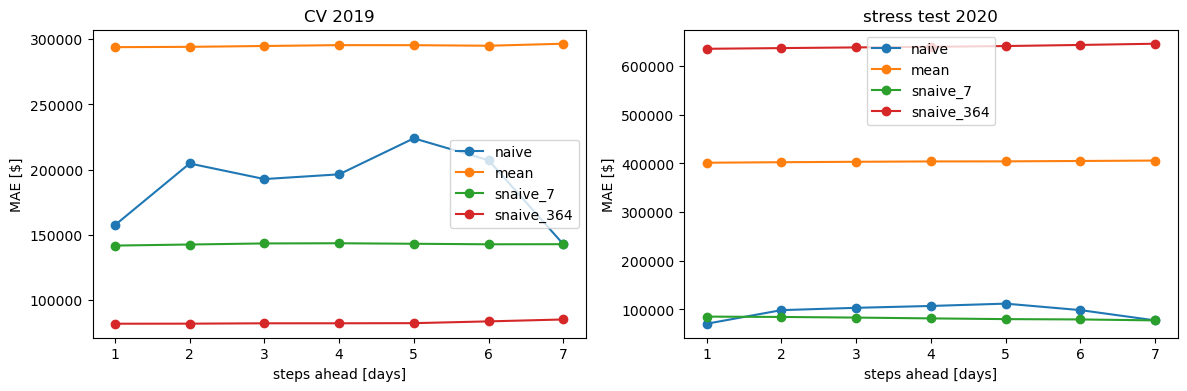

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, res, title in zip(ax, [cv, stress], ['CV 2019', 'stress test 2020']):
    pd.DataFrame({n: np.abs(yt - yh).mean() for n, (yt, yh) in res.items()}).plot(ax=a, marker='o')
    a.set(xlabel='steps ahead [days]', ylabel='MAE [$]', title=title)

**Observations:**
* **CV 2019:** the yearly seasonal naive is by far the best (MAPE ≈ 6.5%): last year's same weekday already captures the weekly + yearly + holiday pattern. The weekly seasonal naive follows (≈ 11.7%). These are the scores a model must beat.
* The naive error oscillates with the horizon (it ignores the weekly cycle); at $h=7$ it coincides with the weekly seasonal naive.
* **Stress test 2020:** the ranking flips. Methods with long memory (yearly seasonal naive, mean) fail completely (MAPE 96-143%), while naive and weekly seasonal naive, which only use the last days, adapt (≈ 13.6%). A good model should combine the yearly/weekly pattern with the **recent level**.

### 4.5 Residual check of the best baseline
If the 1-step-ahead errors are still autocorrelated, there is information left that a better model can exploit (Ljung-Box H0: no autocorrelation up to the given lag).

,lb_stat,lb_pvalue
7,302.790180,1.534032e-61
14,365.390824,2.420159e-69


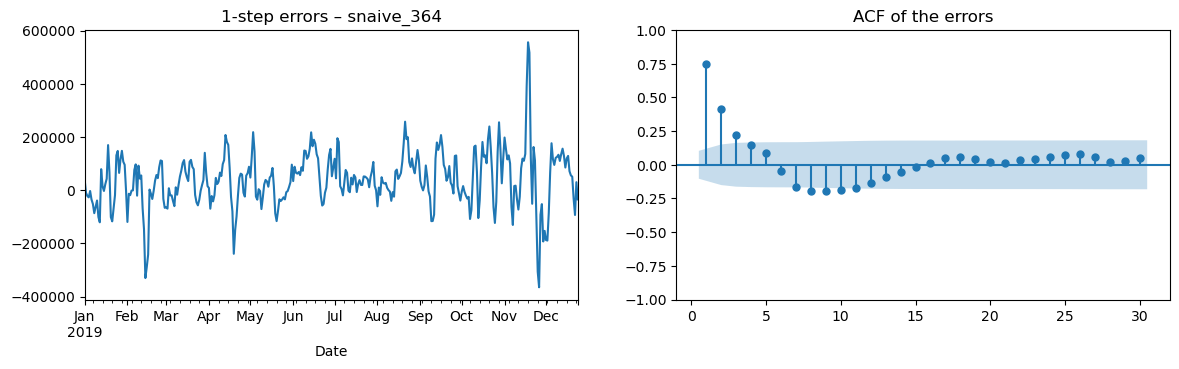

In [17]:
best = scores(cv).index[0]
e1 = cv[best][0][1] - cv[best][1][1]           # 1-step-ahead errors in 2019
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
e1.plot(ax=ax[0], title=f'1-step errors – {best}')
plot_acf(e1, lags=30, zero=False, ax=ax[1], title='ACF of the errors')
sm.stats.acorr_ljungbox(e1, lags=[7, 14])

**Observations:**
* The 1-step errors of the yearly seasonal naive are strongly autocorrelated (ρ₁ ≈ 0.75, Ljung-Box p ≈ 0): when this year is above last year, it stays above for several days.
* There is therefore information left: a model that corrects the seasonal forecast using the recent errors (e.g. ARIMA / ETS on log y, or seasonal naive + AR correction) should improve on it.

## 5. Model building
### 5.1 Candidate models
All models work on **log y** (section 3.1) and are fitted with `statsforecast`; orders / components are selected automatically by AICc.

| Model | Weekly season | Yearly season | Idea |
|---|---|---|---|
| **ETS** | $m=7$ | – | AutoETS: exponential smoothing of level (+ trend) and weekly pattern |
| **SARIMA** | $m=7$ | – | AutoARIMA; the tests in 3.2 suggest $D=1$ |
| **SARIMA + Fourier** | $m=7$ | 10 Fourier pairs | dynamic harmonic regression: smooth yearly shape + ARIMA errors |
| **ARIMA + lag364** | $m=7$ | $\log y_{t-364}$ as regressor | yearly seasonal naive corrected by ARIMA errors (motivated by 4.5) |

Both regressors are known in advance over the whole horizon ($h \le 7 < 364$), so they can be used for forecasting.

In [18]:
t = np.arange(len(y))
fourier = np.column_stack([f(2 * np.pi * k * t / 365.25) for k in range(1, 11) for f in (np.sin, np.cos)])
lag364 = np.log(y).shift(364).values[:, None]     # NaN in 2013: this is why the estimation starts in 2014

models = {
    'ETS':              (AutoETS(season_length=7), None),
    'SARIMA':           (AutoARIMA(season_length=7), None),
    'SARIMA + Fourier': (AutoARIMA(season_length=7), fourier),
    'ARIMA + lag364':   (AutoARIMA(season_length=7), lag364),
}

### 5.2 Fit and CV
To keep the runtime low, parameters are **estimated once** on 2014-2018. In the CV, at each origin the fitted model is only **updated** with the new observations (`forward`: same parameters, state recomputed on $y_{\le t}$), the equivalent of `refit=False` in `statsforecast.cross_validation`. Re-estimating at every one of the ~650 origins would take tens of minutes for practically identical 2019 forecasts.

In [19]:
FIT = slice('2014-01-01', '2018-12-31')        # estimation window
s0 = y.index.get_loc(pd.Timestamp(FIT.start))

def sf_forecaster(model, X=None, y_fit=y):
    '''Fits a statsforecast model on log y_fit over FIT and returns f(y_train, h) to be used in rolling_cv.'''
    n_fit = len(y.loc[FIT])
    model.fit(np.log(y_fit.values[s0:s0 + n_fit]), X=None if X is None else X[s0:s0 + n_fit])
    def f(y_tr, h, level=None):
        n = len(y_tr)
        kw = {} if X is None else dict(X=X[s0:n], X_future=X[n:n + h])
        out = model.forward(y=np.log(y_tr.values[s0:]), h=h, level=level, **kw)
        # back-transform: exp of the log forecast (= median of the revenue forecast)
        return np.exp(out['mean']) if level is None else {k: np.exp(v) for k, v in out.items()}
    return f

forecasters = {n: sf_forecaster(m, X) for n, (m, X) in models.items()}
for n, (m, X) in models.items():
    print(f'{n:18s}', m.model_['method'] if n == 'ETS' else arima_string(m.model_))

for n, f in forecasters.items():
    cv[n] = rolling_cv(y, f, '2019-01-01', '2019-12-31')
    stress[n] = rolling_cv(y, f, '2020-01-01', '2020-10-31')

ETS                ETS(A,N,A)
SARIMA             ARIMA(5,0,2)(2,1,0)[7]                   
SARIMA + Fourier   Regression with ARIMA(2,0,4)(1,1,1)[7] errors
ARIMA + lag364     Regression with ARIMA(1,1,2)(2,0,0)[7] errors


**Observations:**
* **ETS(A,N,A)** on log y: no trend, additive weekly season on the log scale (= multiplicative on revenue, consistent with 3.1).
* **SARIMA** chooses $d=0, D=1$: exactly what the ADF/KPSS tests of 3.2 suggested.
* **ARIMA + lag364** no longer needs the seasonal difference ($D=0$), since the regressor already carries the weekly and yearly pattern; a regular difference ($d=1$) handles the slowly changing year-over-year ratio.

## 6. Results
### 6.1 Model selection (CV 2019) and stress test (2020)

In [20]:
res = pd.concat({'CV 2019': scores(cv), 'stress 2020': scores(stress)}, axis=1)
res.sort_values(('CV 2019', 'MAE')).style.format('{:,.2f}').highlight_min(color='lightgreen')

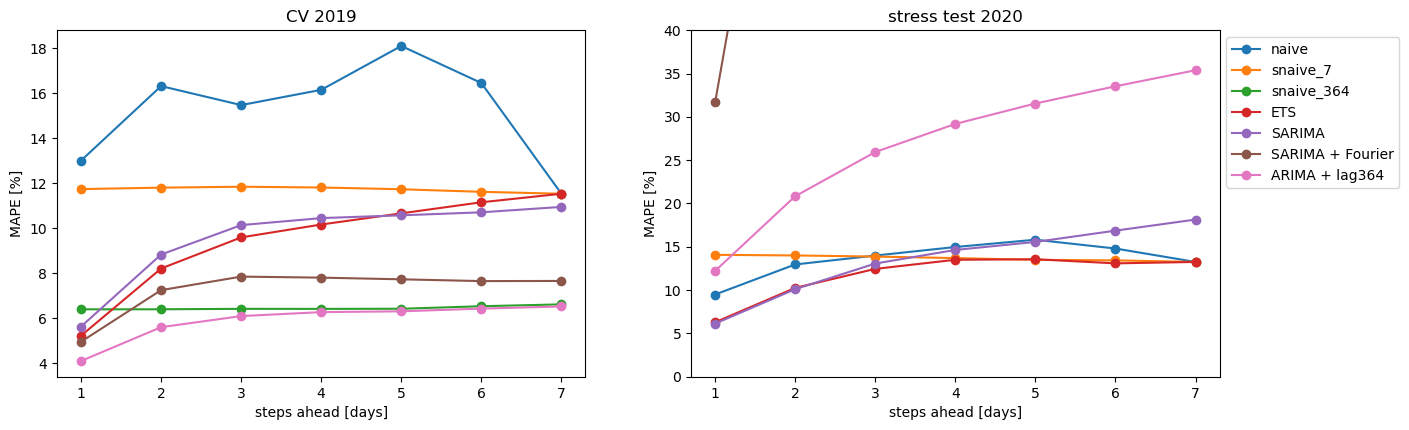

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, res_, title in zip(ax, [cv, stress], ['CV 2019', 'stress test 2020']):
    mape_h = pd.DataFrame({n: (np.abs(yt - yh) / yt).mean() * 100 for n, (yt, yh) in res_.items()})
    mape_h.drop(columns='mean').plot(ax=a, marker='o', legend=False)   # 'mean' is off the scale
    a.set(xlabel='steps ahead [days]', ylabel='MAPE [%]', title=title)
ax[1].set_ylim(0, 40); ax[1].legend(bbox_to_anchor=(1, 1));

**Observations:**
* **CV 2019 → selected model: ARIMA + lag364** (MAPE 5.9%, MAE −11% vs the best baseline). The gain is largest at short horizons (h=1: ≈4% vs 6.4%), where the ARIMA errors correct last year's value with the recent deviation; for $h \ge 4$ it converges to the yearly seasonal naive.
* ETS and SARIMA are good at $h=1$ but degrade towards ≈11% at $h=7$: without yearly information they cannot do better than the weekly pattern. Adding the yearly cycle (Fourier or lag364) keeps the error flat over the horizon.
* **Stress test 2020:** models that rely on the yearly cycle (snaive_364, Fourier, and at longer horizons also lag364) fail, because last year / the average yearly shape no longer describe the new regime. ETS (11.8%) and SARIMA (13.5%), which only follow the recent level, are the most robust.

### 6.2 Residual diagnostics of the selected model
In-sample one-step residuals (log scale) on the estimation window: ideally uncorrelated, centred and roughly normal.

,lb_stat,lb_pvalue
7,7.752637,0.354911
14,21.493719,0.089633


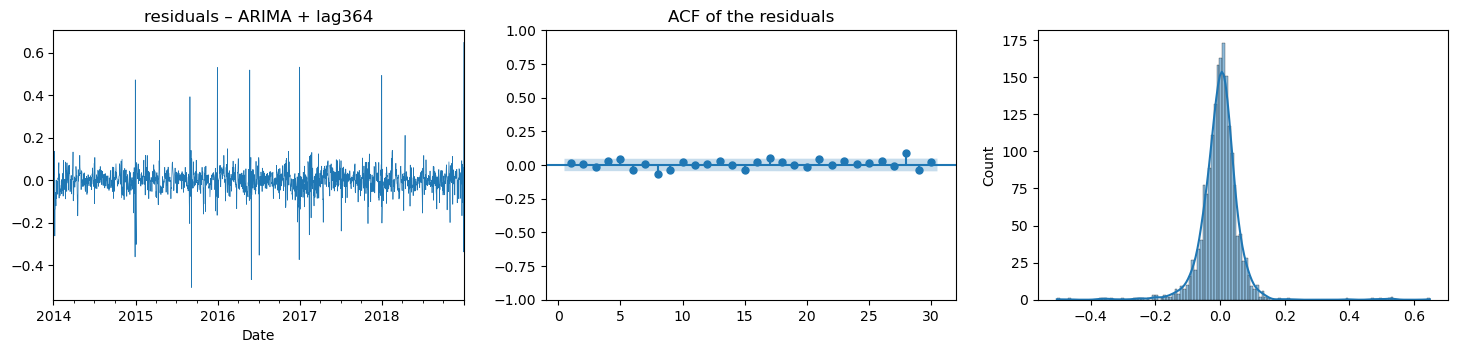

In [22]:
best = scores({n: cv[n] for n in models}).index[0]
m, X = models[best]
resid = pd.Series(np.log(y.loc[FIT].values) - m.predict_in_sample()['fitted'], y.loc[FIT].index)

fig, ax = plt.subplots(1, 3, figsize=(18, 3.5))
resid.plot(ax=ax[0], lw=0.5, title=f'residuals – {best}')
plot_acf(resid, lags=30, zero=False, ax=ax[1], title='ACF of the residuals')
sb.histplot(resid, kde=True, ax=ax[2])
sm.stats.acorr_ljungbox(resid, lags=[7, 14])

**Observations:**
* No significant autocorrelation left (Ljung-Box p = 0.35 at lag 7, 0.09 at lag 14): the model extracts the linear structure of the series.
* Residuals are centred but heavy-tailed: the isolated spikes recur every year at specific dates → holidays (some of them moving, e.g. Thanksgiving), not captured by a 364-day lag. These could be handled with holiday dummies or outlier treatment.

### 6.3 Outlier treatment
**Why we care:** outliers (here holidays and special days) bias the estimated parameters and the AICc order selection, inflate the residual variance (too wide prediction intervals) and, through `lag364`, last year's spike is copied into this year's forecast.

**Remove or impute?** In a time series we **impute**: removing a day breaks the regular daily grid, the weekly lags and `lag364`. We use the **Hampel filter** of the course on the MSTL remainder of log y (so that seasonality is not flagged): a point is an outlier if it is more than 3 robust std (1.4826·MAD) from the median of a centred 15-day window, and it is replaced by that median. Only the **training data (≤ 2018)** is cleaned; the centred window is fine there because it is not used to forecast. The model is still evaluated on the real values.

outliers: 57 days (2.6%)


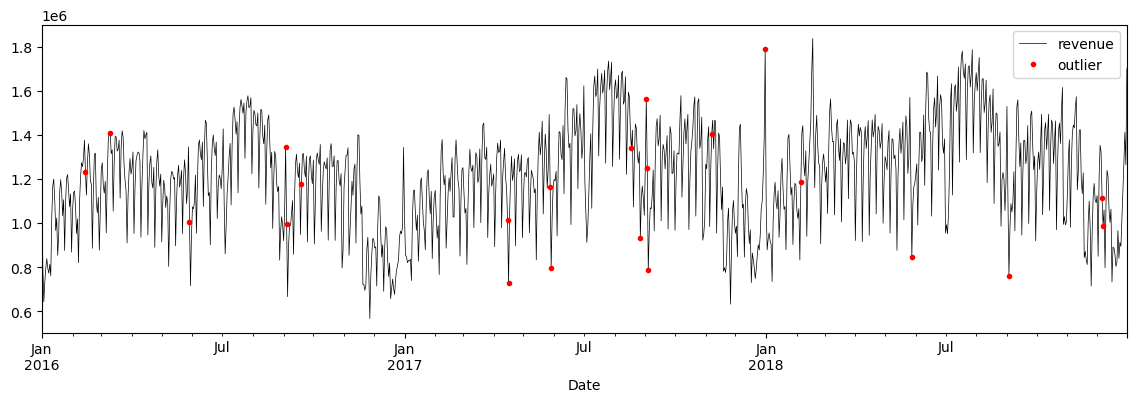

In [23]:
r = MSTL(np.log(y.loc[:'2018']), periods=(7, 365)).fit().resid
med = r.rolling(15, center=True, min_periods=1).median()
mad = 1.4826 * (r - med).abs().rolling(15, center=True, min_periods=1).median()
is_out = (r - med).abs() > 3 * mad
out = is_out[is_out].index
y_clean = y.copy()
y_clean[out] = y[out] * np.exp(med - r)[out]          # remainder -> local median
print(f'outliers: {len(out)} days ({is_out.mean():.1%})')

ax = y.loc['2016':'2018'].plot(lw=0.5, c='k', label='revenue')
y[out].loc['2016':].plot(ax=ax, ls='', marker='o', c='r', ms=3, label='outlier')
ax.legend();

In [24]:
# same model, estimated on the cleaned series (also used for the lag-364 regressor)
lag364_clean = np.log(y_clean).shift(364).values[:, None]
f_clean = sf_forecaster(AutoARIMA(season_length=7), lag364_clean, y_clean)
name = best + ' (cleaned)'
cv[name] = rolling_cv(y, f_clean, '2019-01-01', '2019-12-31')
stress[name] = rolling_cv(y, f_clean, '2020-01-01', '2020-10-31')
pd.concat({'CV 2019': scores({n: cv[n] for n in [best, name]}),
           'stress 2020': scores({n: stress[n] for n in [best, name]})}, axis=1).round(2)

CV 2019              stress 2020             
                               MAE  nMAE MAPE %         MAE  nMAE MAPE %
ARIMA + lag364            73727.37  0.46   5.90   116198.57  2.73  26.95
ARIMA + lag364 (cleaned)  76549.64  0.48   6.22   109322.34  2.50  24.99

**Observations:**
* The filter flags 57 days (2.6% of 2013-2018), mostly holidays and isolated drops/spikes.
* Cleaning does **not** help in 2019 (MAE 76.5k vs 73.7k, MAPE 6.2% vs 5.9%) and helps only slightly in 2020 (MAPE 25.0% vs 27.0%).
* Reason: many of these "outliers" are fixed-date holidays that repeat every year. With `lag364` they are **predictable**, so replacing them with the local median removes useful information from the regressor. Outliers are only harmful when they are not repeated.
* We keep the model estimated on the original data. A better treatment would target only moving holidays (e.g. Thanksgiving) with dummies.

### 6.4 Example forecasts
7-days-ahead forecasts of the selected model with 80% / 95% prediction intervals, for a few origins in 2019.

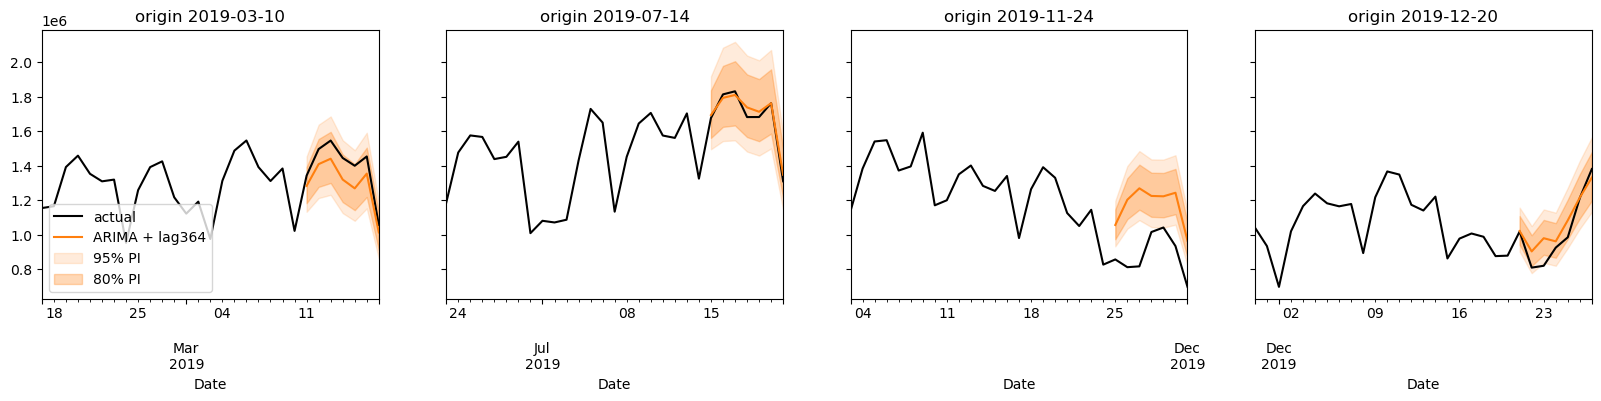

In [25]:
origins = ['2019-03-10', '2019-07-14', '2019-11-24', '2019-12-20']
fig, ax = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)
for a, o in zip(ax, origins):
    fc = forecasters[best](y.loc[:o], H, level=[80, 95])
    idx = pd.date_range(pd.Timestamp(o) + pd.Timedelta(days=1), periods=H)
    y.loc[pd.Timestamp(o) - pd.Timedelta(days=21):idx[-1]].plot(ax=a, c='k', label='actual')
    a.plot(idx, fc['mean'], c='C1', label=best)
    for lv, alpha in [(95, 0.15), (80, 0.3)]:
        a.fill_between(idx, fc[f'lo-{lv}'], fc[f'hi-{lv}'], color='C1', alpha=alpha, label=f'{lv}% PI')
    a.set_title(f'origin {o}')
ax[0].legend(loc='lower left');

### 6.5 Forecasts vs actual values and errors
1-day-ahead forecasts of the selected model over the whole CV (2019) and stress test (2020), with the forecast errors below.

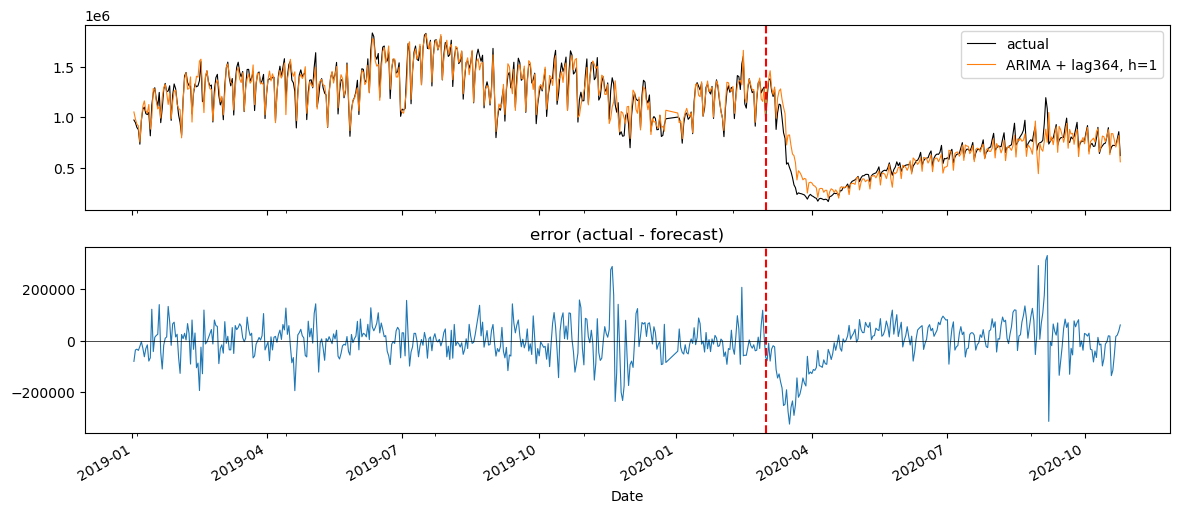

In [26]:
fc1 = pd.concat([cv[best][1][1], stress[best][1][1]])     # h = 1 forecasts, indexed by origin
fc1.index += pd.Timedelta(days=1)                          # ... re-indexed by target day
err = y[fc1.index] - fc1

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
y[fc1.index].plot(ax=ax[0], c='k', lw=0.8, label='actual')
fc1.plot(ax=ax[0], c='C1', lw=0.8, label=f'{best}, h=1')
err.plot(ax=ax[1], lw=0.8, title='error (actual - forecast)')
for a in ax: a.axvline(COVID, c='r', ls='--')
ax[0].legend(); ax[1].axhline(0, c='k', lw=0.5);

**Observations:**
* 2019: the forecast follows the actual series closely; the errors are centred on 0, with isolated spikes around holidays (late November, Christmas / New Year).
* March 2020: the model keeps forecasting the old level for a few days and the errors become large and negative (up to −300k $); after about three weeks the ARIMA errors absorb the new level and the error returns around 0.
* Summer-autumn 2020: the errors are again centred, but larger spikes appear when `lag364` copies a 2019 pattern (e.g. a holiday) that the COVID regime does not repeat.

### 6.6 Conclusions
* **Selected model: regression of log revenue on its value 52 weeks before, with ARIMA(1,1,2)(2,0,0)[7] errors.** Under normal conditions (2019) it forecasts 1-7 days ahead with MAPE ≈ 5.9% (4% at 1 day), beating all baselines and the other statistical models, with white-noise residuals.
* **Weak points:** moving holidays (e.g. Thanksgiving 2019, origin 2019-11-24 above, is aligned with a normal day of 2018) and structural breaks: after March 2020 last year's value is misleading and the model degrades to MAPE ≈ 27%.
* **In practice:** use ARIMA + lag364 in a stable regime and monitor its errors; after a break switch to a model that only uses the recent level (ETS) until a year of "new normal" data is available. Outlier cleaning (Hampel filter, 6.3) did not improve the 2019 CV, because fixed-date holidays are already predicted through `lag364`. Possible improvements: dummies for moving holidays, re-estimating the parameters after the break, a combination of ETS and ARIMA + lag364.